# Accurate RMS

A normal RMS calculation on a fixed size analysis window is not accurate for periodic signals.

* Windowing effects occur, because there might be a fractional number of periods in the analysis window.
* An unsettled AC coupling capacitor will cause a slow discharge of the signal, which will cause a slow drift in the AC RMS value.


Ideas:

* Detect periodic signals, calculate the RMS just over the period. (zero crossings)
* Fit a slow ac drift to a trend and subtract it, before the RMS calculation. Constant, linear or cubic

Because none of these methods use a proper reconstruction of the signal.
Some frequencies will be more accurate than others.
E.g. fs/4 will have serious issues when there is an initial random phase shift.
(This is behavior is normal).


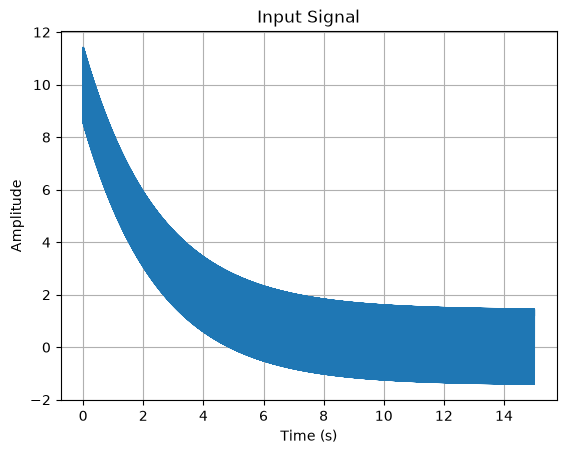

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SIM_DURATION = 15

fs = 102400
t = np.arange(0, SIM_DURATION, 1/fs)

ac_tau = 2.5
initial_dc = 10

# simulate slow decay
decay_start = 0.0 # seconds
exp_decay = np.exp(-(t-decay_start)/ac_tau)
exp_decay[:int(decay_start * fs)] = 0

# simulate periodic signal (or sweep)
# For simplicty we use a sine with an rms of 1
signal_type = "sine"
accurate_rms = 1
phase_shift = 0.1
if signal_type == "sine":
    f = 1000 / (2 * np.pi)
    sine_signal = np.sqrt(2) * accurate_rms * np.sin(2*np.pi*f*t + phase_shift)
elif signal_type == "sweep":
    f_start = 12.5
    f_end = fs/2
    f = np.linspace(f_start, f_end, len(t))
    sine_signal = np.sqrt(2) * accurate_rms * np.sin(2*np.pi*f*t + phase_shift)

# to test the stability with when noise is present
# (i'd expect the zero crossings to be less stable with noise)
noise = 0
# noise_floor = -60 # dB
# noise_ampl = 10**(noise_floor/20)
# noise = np.random.normal(0, noise_ampl, len(t))
y = initial_dc * exp_decay + sine_signal + noise



plt.plot(t, y)
plt.title("Input Signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()


In [2]:
analysis_window = 16384
if signal_type == "sine":
    print("analysis_window", analysis_window)
    print("periods_per_window", analysis_window / fs * f)
    analysis_dt = analysis_window / fs

    samples_per_period = fs / f
    max_num_periods = int(analysis_window / samples_per_period)
    frac_samples = samples_per_period*max_num_periods
    print(f"samples_per_period: {samples_per_period}")
    print(f"exact frac_samples: {frac_samples}")

analysis_window 16384
periods_per_window 25.464790894703256
samples_per_period: 643.3981754551896
exact frac_samples: 16084.95438637974


In [3]:
def iter_windows(signal=y):
    for win in range(0, len(signal), analysis_window):
        y_win = signal[win:win+analysis_window]
        if len(y_win) < analysis_window:
            break
        yield y_win

In [4]:

def _interp_zero_crossing(y, i):
    """Fractional index of the zero between samples i and i+1."""
    y0 = y[i]
    y1 = y[i + 1]
    dy = y1 - y0
    assert y0 * y1 <= 0, "y0 and y1 must have opposite signs"
    if dy == 0:
        return float(i)
    return i - y0 / dy

def get_frac_zero_crossings(y_win):
    """
    Returns the index bounds (start, end) for the first and last zero crossing in y_win,
    as fractional indices using linear interpolation between the samples.
    Also returns the number of crossings. If none are found, returns (None, None, 0).
    """
    y = np.asarray(y_win)
    zero_crossings = np.where(np.diff(np.signbit(y)))[0]
    n = (len(zero_crossings) - 1) // 2
    if n <= 0:
        return (None, None, 0)
    zero_a = _interp_zero_crossing(y, zero_crossings[0])
    zero_b = _interp_zero_crossing(y, zero_crossings[n*2])
    return (zero_a, zero_b, n)


def frac_dc(y_win, n):
    """Fractional dc over n fractional samples"""
    frac = n - int(n)
    avg_sum = np.sum(y_win[:int(n)])
    if frac > 0.0:
        avg_sum += y_win[int(n)] * frac
    return avg_sum / n

def frac_rms(y_win, n):
    """RMS over n fractional samples"""
    frac = n - int(n)
    avg = frac_dc(y_win, n)

    x = np.sum((y_win[:int(n)]-avg)**2)
    if frac > 0.0:
        x += (y_win[int(n)]-avg)**2 * frac
    return np.sqrt(x / n)


## Baseline comparison

This computes these RMS values:
* Normal RMS
* Linear trend removal
* Fractional RMS
* Fractional RMS with linear trend removal

For the fractional RMS we use zero-crossings to detect the period.

In [5]:


frac_samples_list = []
dc_list = []
rms_list = []
frac_dc_list = []
frac_rms_list = []
m_list = []
linear_rms_list = []
linear_frac_rms_list = []

f_approx = f + 0.02
f_approx = f


for y_win in iter_windows():
    dc_list.append(np.mean(y_win)) # plain dc
    y_win_ac = y_win - dc_list[-1] # plain ac
    rms_list.append(np.sqrt(np.mean(y_win_ac**2))) # plain ac rms

    # detect zero crossings & frequency
    zero_a, zero_b, n = get_frac_zero_crossings(y_win_ac)
    frac_samples_list.append((zero_a, zero_b, n))
    if zero_a is None:
        frac_dc_list.append(dc_list[-1])
        linear_frac_rms_list.append(rms_list[-1])

        continue

    # Fractional dc calculation
    frac_dc_list.append(frac_dc(y_win, zero_b-zero_a))

    # helper variables
    f_approx = fs/((zero_b-zero_a)/n)
    samples_per_period = fs/f_approx
    # samples_per_period = (zero_b-zero_a)/n # Same (but optimized)
    max_num_periods = int(analysis_window / samples_per_period)
    frac_samples = samples_per_period*max_num_periods

    # Fractional rms, should suppress the windowing effects.
    # But a slow decay in the signal will cause a slow drift in the rms.
    frac_rms_list.append(frac_rms(y_win, frac_samples))

    # Linear trend removal
    # Now we split the window into two parts (and calculate the fractional dc)
    # We assume that the signal stays the same
    max_num_periods_2 = int(analysis_window / 2 / samples_per_period)
    frac_samples_2 = samples_per_period*max_num_periods_2
    frac_dc_1 = frac_dc(y_win[:int(frac_samples_2+1)], frac_samples_2)
    frac_dc_2 = frac_dc(y_win[-int(frac_samples_2+2):], frac_samples_2)
    t1 = frac_samples_2 / 2
    t2 = (len(y_win) - int(frac_samples_2+1)) + t1
    m = (frac_dc_2 - frac_dc_1) / (t2 - t1)
    m_list.append(m)
    y_win_sub_lin = y_win - m * np.arange(0, len(y_win))
    y_win_sub_lin -= np.mean(y_win_sub_lin)

    # Calculate the rms value with removed linear trend. (over the whole window)
    linear_rms_list.append(np.sqrt(np.mean(y_win_sub_lin[int(zero_a):int(zero_b)]**2)))

    # Calculate the factional rms with removed linear trend.
    n_frac = zero_b - zero_a
    rms_frac = frac_rms(y_win_sub_lin[int(zero_a):], n_frac)
    linear_frac_rms_list.append(rms_frac)



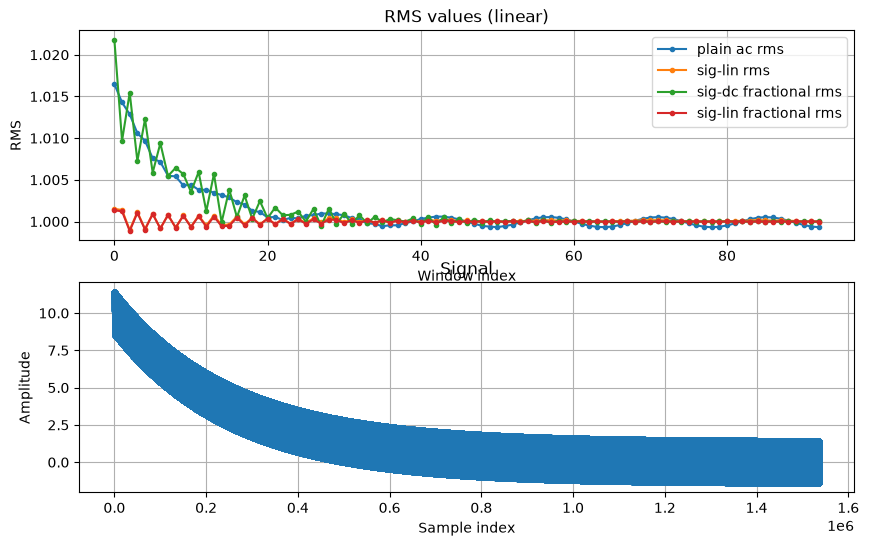

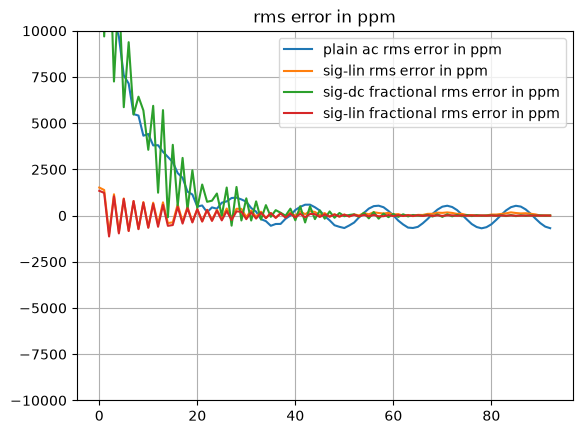

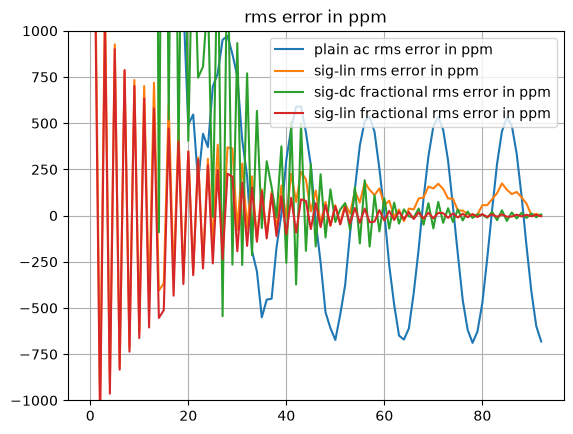

In [6]:

# linear-scale RMS value plot
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(rms_list, ".-", label="plain ac rms")
plt.plot(linear_rms_list, ".-", label="sig-lin rms")
plt.plot(frac_rms_list, ".-", label="sig-dc fractional rms")
plt.plot(linear_frac_rms_list, ".-", label="sig-lin fractional rms")
plt.title("RMS values (linear)")
# plt.ylim(0.99, 1.01)
plt.ylabel("RMS")
plt.xlabel("Window index")
plt.legend()
plt.grid()
plt.subplot(2, 1, 2)
# plot the signal
plt.plot(y, ".")
plt.title("Signal")
plt.xlabel("Sample index")
plt.ylabel("Amplitude")
plt.grid()
plt.show()


# Linear RMS error plot (log scale, as before)
def plot_rms_error(ppm_limit=100):
    plt.plot((np.array(rms_list)-1)*1e6, label="plain ac rms error in ppm")
    plt.plot((np.array(linear_rms_list)-1)*1e6, label="sig-lin rms error in ppm")
    plt.plot((np.array(frac_rms_list)-1)*1e6, label="sig-dc fractional rms error in ppm")
    plt.plot((np.array(linear_frac_rms_list)-1)*1e6, label="sig-lin fractional rms error in ppm")
    # plt.yscale("log")
    plt.title("rms error in ppm")
    # plt.ylim(-10000, 10000)
    plt.ylim(-ppm_limit, ppm_limit)
    plt.legend()
    plt.grid()
    plt.show()


plot_rms_error(10000)
plot_rms_error(1000)

## Improved linear drift + fractional RMS

Same idea as the baseline sig-lin fractional RMS, but the linear trend is not taken from two half-window DC estimates.

**Drift.** A centered moving average of `k` periods (`k = max(1, floor(n_cycles/4))`) cancels content that repeats at that period. A least-squares line is fit to that moving average over the interior of the window and subtracted.

**Period.** Zero crossings start on a rough linear detrend, then are refined on the MA-detrended residual (and the line is refit). A single raw-signal linear detrend correlates with a non-integer-period tone and biases the period even when no drift is present — that was why this path used to lose to sig-lin on flat windows.

**Fallback.** If there are not enough crossings or the window cannot support a line fit (~2 periods), the plain window AC RMS is returned and `strategy` is `window_ac` instead of `linear_frac`.

Implemented in `dsp.rms.linear` / `dsp.rms.linear_numba`.

strategies: {'linear_frac': 93}
linear_frac windows: median |error| 0.047 ppm, max 2.713 ppm


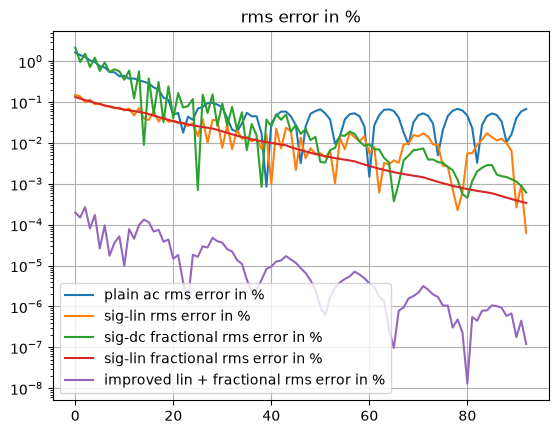

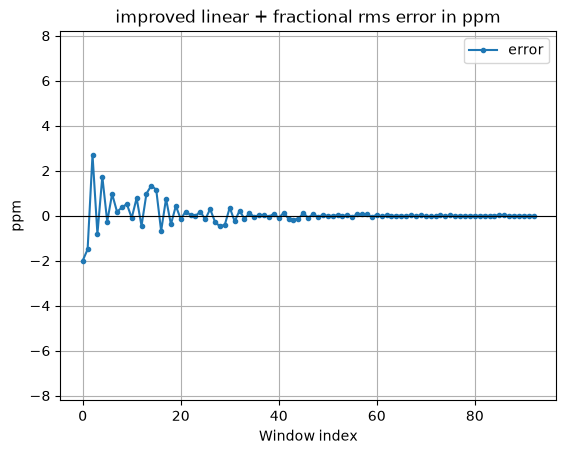

In [7]:
from collections import Counter

from dsp.rms.linear_numba import linear_fractional_rms

lin_imp_rms_list = []
lin_imp_strategy_list = []
lin_imp_f_list = []
for y_win in iter_windows():
    est = linear_fractional_rms(y_win, fs)
    lin_imp_rms_list.append(est.rms)
    lin_imp_strategy_list.append(est.strategy)
    lin_imp_f_list.append(est.frequency_hz)

lin_imp_rms = np.asarray(lin_imp_rms_list, dtype=float)
lin_imp_ppm = (lin_imp_rms - accurate_rms) / accurate_rms * 1e6
lin_imp_ok = np.array([s == "linear_frac" for s in lin_imp_strategy_list])
print("strategies:", dict(Counter(lin_imp_strategy_list)))
if lin_imp_ok.any():
    print(
        f"linear_frac windows: median |error| {np.median(np.abs(lin_imp_ppm[lin_imp_ok])):.3f} ppm, "
        f"max {np.max(np.abs(lin_imp_ppm[lin_imp_ok])):.3f} ppm"
    )
else:
    print("no linear_frac windows in this run")

plt.plot(np.abs((np.array(rms_list) - accurate_rms) * 100), label="plain ac rms error in %")
plt.plot(np.abs((np.array(linear_rms_list) - accurate_rms) * 100), label="sig-lin rms error in %")
plt.plot(np.abs((np.array(frac_rms_list) - accurate_rms) * 100), label="sig-dc fractional rms error in %")
plt.plot(np.abs((np.array(linear_frac_rms_list) - accurate_rms) * 100), label="sig-lin fractional rms error in %")
plt.plot(np.abs(lin_imp_ppm) * 1e-4, label="improved lin + fractional rms error in %")
plt.yscale("log")
plt.title("rms error in %")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(lin_imp_ppm, ".-", label="error")
plt.axhline(0, color="k", lw=0.8)
if lin_imp_ok.any():
    span = np.percentile(np.abs(lin_imp_ppm[lin_imp_ok]), 99)
    plt.ylim(-4 * span, 4 * span)
plt.title("improved linear + fractional rms error in ppm")
plt.xlabel("Window index")
plt.ylabel("ppm")
plt.legend()
plt.grid()
plt.show()

## Cubic drift + fractional RMS

The waveform itself is not modelled. Each analysis window is split into a slow cubic drift and a residual. The period is the lag that makes the residual repeat, and the RMS is the fractional RMS over a whole number of those periods.

**Drift.** A centered moving average of one period cancels whatever shape repeats at that period, so the average follows the drift only. A cubic in normalized time is least-squares fit to a subsample of that average (`fit_stride`) and evaluated over the full window.

**Period.** A zero-crossing hint (or the previous window's period) seeds a two-stage search:

1. Freeze the cubic at the hint and refine the lag over ±0.6 Hz. The residual is fixed, so each trial is only a shift-and-compare.
2. Rebuild the cubic at every trial period and refine over ±0.05 Hz.

The cost is the mean-square change of the residual after a shift of one period.

**RMS.** Subtract the cubic at the refined period, then take `frac_rms` over `floor(N / period)` periods. Error is in ppm against `accurate_rms`. The window that holds the decay step is left out of the median and max: a cubic cannot follow that discontinuity.

Implemented in `cubic_frac_rms.py`.

cubic + fractional RMS: median |error| 0.009 ppm, max 0.019 ppm (window 4 holds the decay step and is -0 ppm)


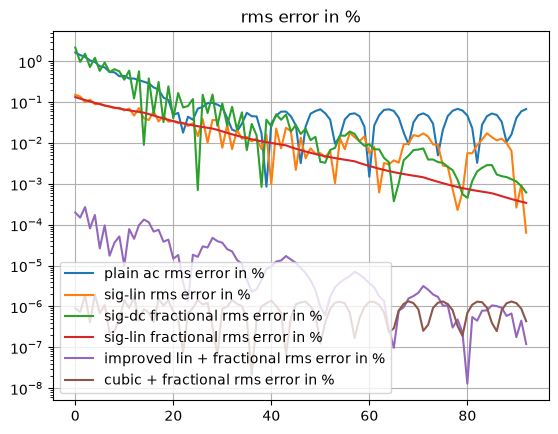

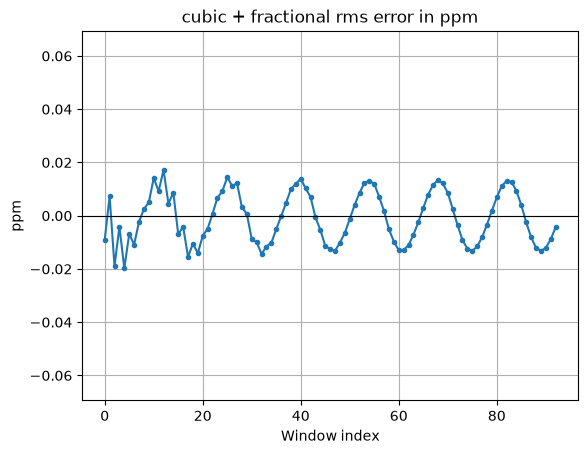

In [8]:
from dsp.rms import cubic_fractional_rms

cubic_frac_rms_list = []
cubic_frac_f_list = []
period_state = None
for y_win in iter_windows():
    rms, freq, period_state = cubic_fractional_rms(y_win, fs, period_state)
    cubic_frac_rms_list.append(rms)
    cubic_frac_f_list.append(freq)

cubic_frac_rms = np.asarray(cubic_frac_rms_list, dtype=float)
cubic_frac_ppm = (cubic_frac_rms - accurate_rms) / accurate_rms * 1e6
valid = np.isfinite(cubic_frac_ppm)
worst = int(np.nanargmax(np.abs(cubic_frac_ppm)))
keep = valid.copy()
keep[worst] = False
print(
    f"cubic + fractional RMS: median |error| {np.median(np.abs(cubic_frac_ppm[keep])):.3f} ppm, "
    f"max {np.max(np.abs(cubic_frac_ppm[keep])):.3f} ppm "
    f"(window {worst} holds the decay step and is {cubic_frac_ppm[worst]:.0f} ppm)"
)

plt.plot(np.abs((np.array(rms_list) - accurate_rms) * 100), label="plain ac rms error in %")
plt.plot(np.abs((np.array(linear_rms_list) - accurate_rms) * 100), label="sig-lin rms error in %")
plt.plot(np.abs((np.array(frac_rms_list) - accurate_rms) * 100), label="sig-dc fractional rms error in %")
plt.plot(np.abs((np.array(linear_frac_rms_list) - accurate_rms) * 100), label="sig-lin fractional rms error in %")
plt.plot(np.abs(lin_imp_ppm) * 1e-4, label="improved lin + fractional rms error in %")
plt.plot(np.abs(cubic_frac_ppm) * 1e-4, label="cubic + fractional rms error in %")
plt.yscale("log")
plt.title("rms error in %")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(cubic_frac_ppm, ".-")
plt.axhline(0, color="k", lw=0.8)
span = np.percentile(np.abs(cubic_frac_ppm[keep]), 99)
plt.ylim(-4 * span, 4 * span)
plt.title("cubic + fractional rms error in ppm")
plt.xlabel("Window index")
plt.ylabel("ppm")
plt.grid()
plt.show()


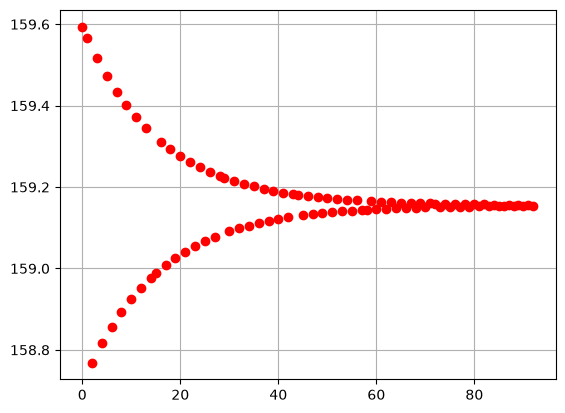

In [9]:


# zero_a, zero_b, n = get_frac_zero_crossings(y_win)
# print(zero_a, zero_b, n)
# plt.plot(y_win, 'x-')
# plt.plot(zero_a, 0, "ro")
# plt.plot(zero_b, 0, "go")
# plt.plot(frac_dc_list)
# plt.plot(frac_dc_list2)
# plt.plot(frac_samples_list)
frac_len = [fs/((x[1]-x[0])/x[2]) for x in frac_samples_list if x[0] is not None]
plt.plot(np.array(frac_len), "ro")
# plt.ylim(-0.1, 0.1)
# plt.xlim(113, 120)
plt.grid()
plt.show()



AC FIR: 25697 taps, fc=10.0 Hz, |H(159.15494309189535 Hz)| = 1 (pre-scale error -171.7651 ppm)


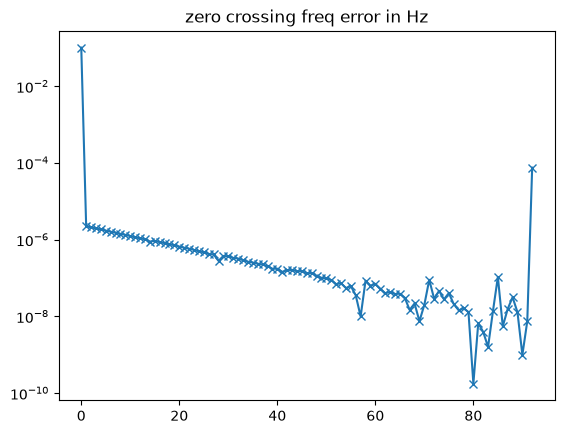

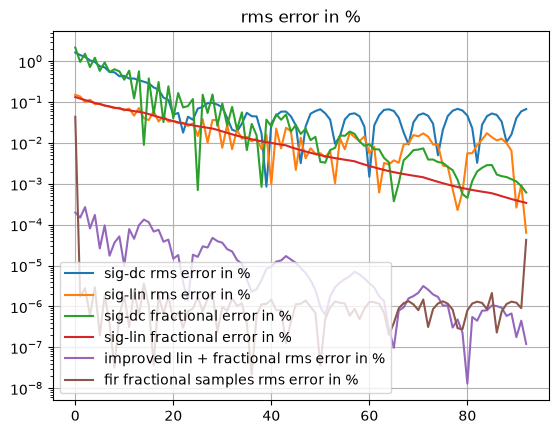

In [10]:

from scipy.signal import kaiserord, firwin, freqz, fftconvolve

# AC coupling: linear-phase FIR highpass, cutoff 20 Hz.
# Kaiser length puts the tone in a flat passband (~140 dB stopband, 30 Hz transition).
# The center tap is adjusted so the DC gain is exactly 0, then the taps are scaled
# so |H(f)| = 1. Zero-phase fftconvolve with odd padding keeps the waveform aligned.
cutoff_hz = 10.0
trans_hz = 20.0
atten_db = 80.0
numtaps, beta = kaiserord(atten_db, trans_hz / (fs / 2))
if numtaps % 2 == 0:
    numtaps += 1

h = firwin(numtaps, cutoff_hz, window=("kaiser", beta), pass_zero=False, fs=fs)
h[(numtaps - 1) // 2] -= np.sum(h)
_, H_f = freqz(h, worN=[2 * np.pi * f / fs])
gain = np.abs(H_f[0])
h = h / gain

delay = (numtaps - 1) // 2
left = 2 * y[0] - y[1:delay + 1][::-1]
right = 2 * y[-1] - y[-delay - 1:-1][::-1]
y_pad = np.concatenate([left, y, right])
y_fir = fftconvolve(y_pad, h, mode="valid")

print(f"AC FIR: {numtaps} taps, fc={cutoff_hz} Hz, |H({f} Hz)| = 1 (pre-scale error {(gain - 1) * 1e6:.4f} ppm)")

fir_frac_rms_list = []
freq_list = []

for y_win in iter_windows(y_fir):
    zero_a, zero_b, n = get_frac_zero_crossings(y_win - y_win.mean())
    freq_list.append(fs/((zero_b-zero_a)/n))

    if zero_a is not None:
        nsamples_2 = zero_b - zero_a
        fir_frac_rms_list.append(frac_rms(y_win, nsamples_2))


plt.plot(np.abs(np.array(freq_list)-f), 'x-')
plt.yscale("log")
plt.title("zero crossing freq error in Hz")
plt.show()


plt.plot(np.abs((np.array(rms_list)-1)*100), label="sig-dc rms error in %")
plt.plot(np.abs((np.array(linear_rms_list)-1)*100), label="sig-lin rms error in %")
plt.plot(np.abs((np.array(frac_rms_list)-1)*100), label="sig-dc fractional error in %")
plt.plot(np.abs((np.array(linear_frac_rms_list)-1)*100), label="sig-lin fractional error in %")
plt.plot(np.abs(lin_imp_ppm) * 1e-4, label="improved lin + fractional rms error in %")
plt.plot(np.abs((np.array(fir_frac_rms_list)-1)*100), label="fir fractional samples rms error in %")
plt.yscale("log")
plt.title("rms error in %")
plt.legend()
plt.grid()
plt.show()


## Cubic drift + fractional RMS

The waveform itself is not modelled. Each analysis window is split into a slow cubic drift and a residual. The period is the lag that makes the residual repeat, and the RMS is the fractional RMS over a whole number of those periods.

**Drift.** A centered moving average of one period cancels whatever shape repeats at that period, so the average follows the drift only. A cubic in normalized time is least-squares fit to a subsample of that average (`fit_stride`) and evaluated over the full window.

**Period.** A zero-crossing hint (or the previous window's period) seeds a two-stage search:

1. Freeze the cubic at the hint and refine the lag over ±0.6 Hz. The residual is fixed, so each trial is only a shift-and-compare.
2. Rebuild the cubic at every trial period and refine over ±0.05 Hz.

The cost is the mean-square change of the residual after a shift of one period.

**RMS.** Subtract the cubic at the refined period, then take `frac_rms` over `floor(N / period)` periods. Error is in ppm against `accurate_rms`. The window that holds the decay step is left out of the median and max: a cubic cannot follow that discontinuity.

Implemented in `cubic_frac_rms.py`.

In [11]:
from dsp.rms import cubic_fractional_rms

cubic_frac_rms_list = []
cubic_frac_f_list = []
period_state = None
for y_win in iter_windows():
    rms, freq, period_state = cubic_fractional_rms(y_win, fs, period_state)
    cubic_frac_rms_list.append(rms)
    cubic_frac_f_list.append(freq)

cubic_frac_rms = np.asarray(cubic_frac_rms_list, dtype=float)
cubic_frac_ppm = (cubic_frac_rms - accurate_rms) / accurate_rms * 1e6
valid = np.isfinite(cubic_frac_ppm)
worst = int(np.nanargmax(np.abs(cubic_frac_ppm)))
keep = valid.copy()
keep[worst] = False
print(
    f"cubic + fractional RMS: median |error| {np.median(np.abs(cubic_frac_ppm[keep])):.3f} ppm, "
    f"max {np.max(np.abs(cubic_frac_ppm[keep])):.3f} ppm "
    f"(window {worst} holds the decay step and is {cubic_frac_ppm[worst]:.0f} ppm)"
)



cubic + fractional RMS: median |error| 0.009 ppm, max 0.019 ppm (window 4 holds the decay step and is -0 ppm)


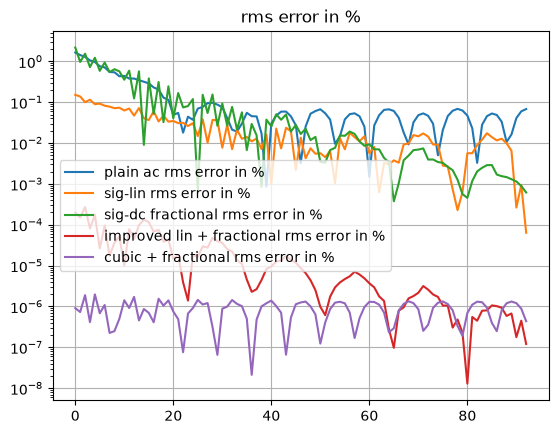

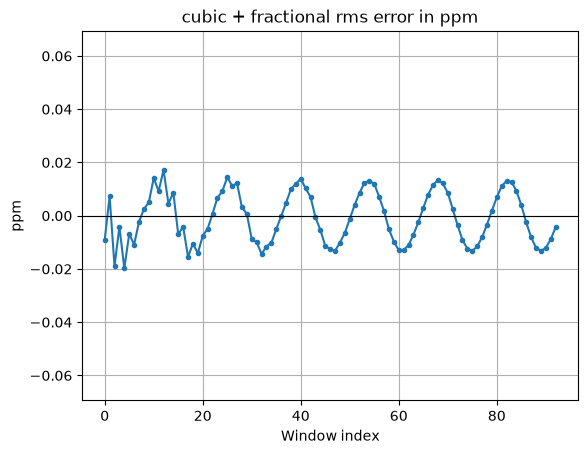

In [12]:


plt.plot(np.abs((np.array(rms_list) - accurate_rms) * 100), label="plain ac rms error in %")
plt.plot(np.abs((np.array(linear_rms_list) - accurate_rms) * 100), label="sig-lin rms error in %")
plt.plot(np.abs((np.array(frac_rms_list) - accurate_rms) * 100), label="sig-dc fractional rms error in %")
plt.plot(np.abs(lin_imp_ppm) * 1e-4, label="improved lin + fractional rms error in %")
plt.plot(np.abs(cubic_frac_ppm) * 1e-4, label="cubic + fractional rms error in %")
plt.yscale("log")
plt.title("rms error in %")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(cubic_frac_ppm, ".-")
plt.axhline(0, color="k", lw=0.8)
span = np.percentile(np.abs(cubic_frac_ppm[keep]), 99)
plt.ylim(-4 * span, 4 * span)
plt.title("cubic + fractional rms error in ppm")
plt.xlabel("Window index")
plt.ylabel("ppm")
plt.grid()
plt.show()
